This is the cutdown companion Jupyter Notebook of Chapter 3, Quantum Circuit Model of Computation, of the second edition of the book titled:
"Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900.
Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

# 3. Quantum Circuit Model of Computation

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, [https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit), and in Robert Loredo's book [Loredo_Qiskit]. 

The companion Jupyter notebook automatically installs the following list of libraries: 
- Numerical Python (NumPy) [NumPy], an open-source Python library that is used in almost every field of science and engineering
- Qiskit [Qiskit], an open-source SDK for working with quantum computers at the level of pulses, circuits, and application modules
- Qiskit visualization support to enable visualization and Jupyter notebooks
- Quantum Toolbox in Python (QuTiP) [QuTiP], which is designed to be a general framework for solving quantum mechanics problems such as systems composed of few-level quantum systems and harmonic oscillators

We recommend using the following online graphical tools:
- IBM Quantum Composer which is a graphical quantum programming tool that lets you drag and drop operations to build quantum circuits and run them on real quantum hardware or simulators [IBM_comp1] [IBM_comp2].
- Grok the Block Sphere, a web-based application that displays the Bloch sphere and shows the action of gates as rotations [Grok].


## Installing NumPy, and Qiskit and importing various modules
### Install NumPy with the following command:

In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit with the following command:

In [2]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit visualization support with the following command:

In [3]:
pip install 'qiskit[visualization]'

Note: you may need to restart the kernel to use updated packages.


### Install qiskit.utils with the following command:

In [4]:
pip install qiskit.utils

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Aer with the following command:

In [5]:
pip install qiskit-aer

Note: you may need to restart the kernel to use updated packages.


### Install QuTiP with the following command:

In [6]:
pip install qutip

Note: you may need to restart the kernel to use updated packages.


### Import NumPy with the following command:

In [7]:
import numpy as np

### Import qiskit.aer

In [8]:
import qiskit_aer
from qiskit_aer import AerSimulator

### Import the required functions and class methods with the following commands.

In [9]:
from qiskit.visualization import array_to_latex, plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere, plot_state_city
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
import qiskit.quantum_info as qi
from qiskit.circuit.library import Initialize

### Import the math libraries with the following commands:

In [10]:
import cmath
import math

### Import QuTiP with the following command:

In [11]:
import qutip

### Hide all runtime warnings

In [12]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# 3.1. Qubits, entanglement, Bloch sphere, Pauli matrices
## 3.1.1. Qubits
## 3.1.2. Tensor ordering of qubits
## 3.1.3 Quantum entanglement
## 3.1.4. Bloch sphere

## 3.1.5. Displaying the Bloch vector corresponding to a statevector

In [1]:
_EPS = 1e-10 # Global variable used to chop small numbers to zero
def check(s):
    num_qubits = math.log2(len(s))

    # Length must be a power of 2
    if num_qubits <= 0 or not num_qubits.is_integer():
        raise Exception("Input complex vector length is not a positive power of 2.")

    num_qubits = int(num_qubits)

    # Bloch sphere only supports 1-qubit states
    if num_qubits != 1:
        raise Exception(
            "Bloch sphere visualization only supports a single-qubit state vector (length 2)."
        )

    # Normalization check
    if not math.isclose(sum(np.abs(s)**2), 1.0, abs_tol=_EPS):
        raise Exception("Norm of complex vector does not equal one.")

In [14]:
def ToBloch(s, show=True, Qiskit=True):
    check(s)
    phi = cmath.phase(s[1]) - cmath.phase(s[0])
    theta = 2 * math.acos(abs(s[0]))
    r = [
        math.sin(theta) * math.cos(phi),
        math.sin(theta) * math.sin(phi),
        math.cos(theta)
    ]
    if show:
        display(array_to_latex(s, prefix="\\text{s} = ", precision = 2))
        display(array_to_latex([theta, phi], prefix="\\text{theta, phi} = ", precision = 2))
        display(array_to_latex(r, prefix="\\text{r} = ", precision = 2))
    if Qiskit:
        display(plot_bloch_vector(r))
    else:
        b = qutip.Bloch()
        b.add_vectors(r)
        b.show()   
    return theta, phi, r

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

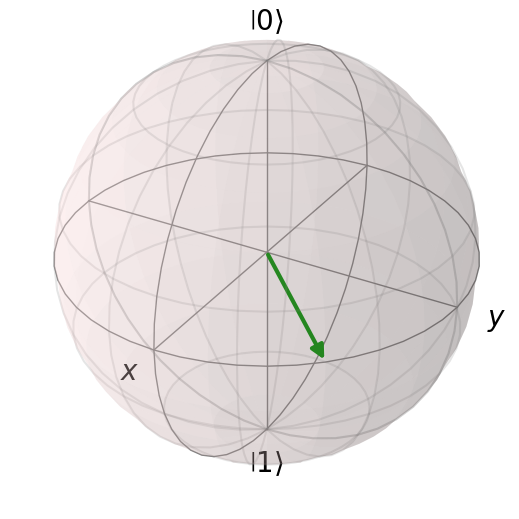

In [15]:
s = [1/math.sqrt(2),complex(0.5, 0.5)]
(theta, phi, r) = ToBloch(s, Qiskit=False)

In [16]:
def ToS(theta, phi, show=True):
  s = [math.cos(theta/2), complex(math.cos(phi) * math.sin(theta/2), math.sin(phi) * math.sin(theta/2))]
  if show:
    display(array_to_latex([theta, phi], prefix="\\text{theta, phi} = ", precision = 2))
    display(array_to_latex(s, prefix="\\text{s} = ", precision = 1))
  return s

In [17]:
s = ToS(np.pi/2, np.pi/4)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 3.1.6. Pauli matrices

### Measurement in the sign basis $\{|+\rangle,|-\rangle\}$

### Decomposing a matrix into the weighted sum of the tensor product of Pauli matrices

# 3.2. Quantum gates
## 3.2.1. Single qubit quantum gates
### X Gate
### H Gate
### General single qubit quantum gate
### Summary of single qubit quantum gates and useful relationships

## 3.2.2. Two qubits quantum gates

## 3.2.3. Three qubits quantum gates

## 3.2.4. Serially wired gates and parallel quantum gates

## 3.2.5. Creation of a Bell state

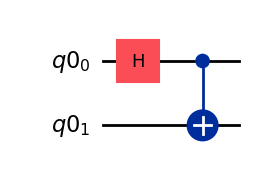

In [18]:
q = QuantumRegister(2)
qc = QuantumCircuit(q)

qc.h(q[0])
qc.cx(q[0], q[1])

qc.draw(output='mpl')

In [19]:
s = qi.Statevector.from_instruction(qc)
s.draw('latex')

<IPython.core.display.Latex object>

In [20]:
rho = qi.DensityMatrix.from_instruction(qc)
rho.draw('latex')

<IPython.core.display.Latex object>

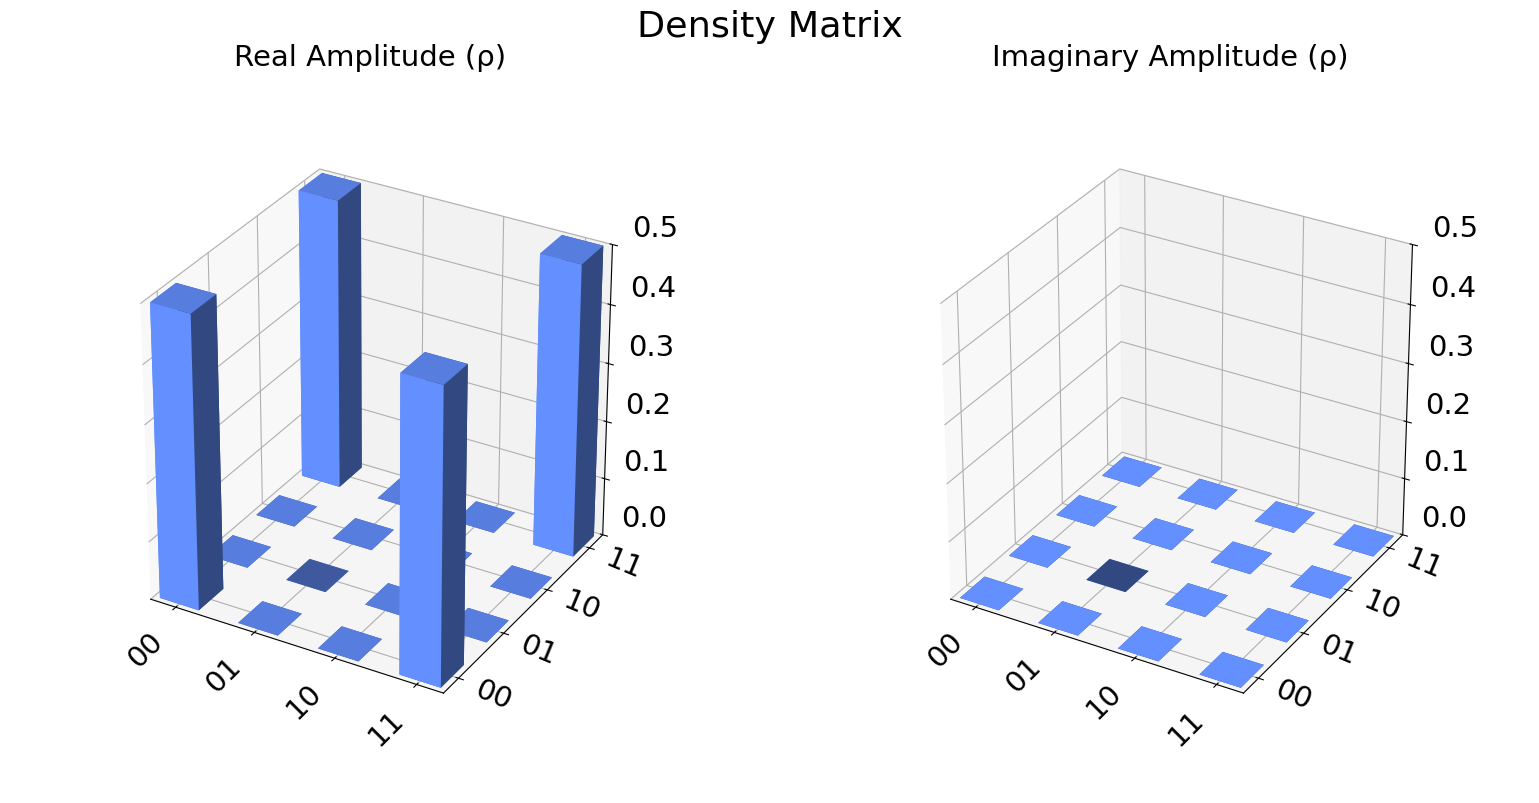

In [21]:
plot_state_city(rho.data, title='Density Matrix')

## 3.2.6. Parallel Hadamard gates

In [22]:
def create_parallel_H(n):
    q = QuantumRegister(n, 'q')
    qc = QuantumCircuit(q)
    for k in range(n):
        qc.h(k)
    return qc

In [23]:
def run_parallel_H(n):
  qc = create_parallel_H(n)
  s = qi.Statevector.from_instruction(qc)
  display(s.draw('latex'))
  display(qc.draw(output='mpl'))
  return

<IPython.core.display.Latex object>

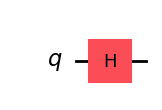

In [24]:
run_parallel_H(1)

<IPython.core.display.Latex object>

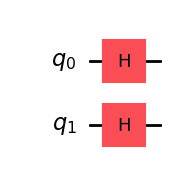

In [25]:
run_parallel_H(2)

<IPython.core.display.Latex object>

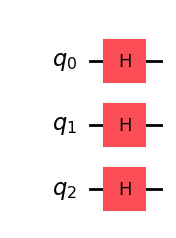

In [26]:
run_parallel_H(3)

# 3.3. Computation driven interference
## 3.3.1. Quantum computation process

## 3.3.2. Simulating interferometric sensing of a quantum superposition of left- and right-handed enantiomer states

In [27]:
from qiskit.circuit.library import UnitaryGate

i = complex(0.0, 1.0)
BS = 1/np.sqrt(2) * np.array([[1,i],[i,1]])
BS = UnitaryGate(BS,'BS')

In [28]:
PBS = np.array([[1,0,0,0],[0,0,0,1],[0,0,1,0],[0,1,0,0]])
PBS = UnitaryGate(PBS,'PBS')

In [29]:
def show(qc):
  display(qc.draw(output='mpl'))
  s = qi.Statevector.from_instruction(qc)
  display(array_to_latex(s, prefix="\\text{state vector} = ", precision = 2))
  return

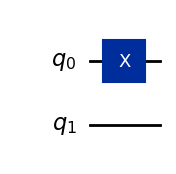

<IPython.core.display.Latex object>

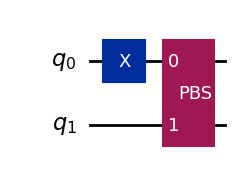

<IPython.core.display.Latex object>

In [30]:
q = QuantumRegister(2, 'q') # register of 2 qubits
# q[0] handedness qubit,|0⟩ left-handed, |1⟩ right-handed
# q[1] direction of propagation qubit, |0⟩ horizontal, |1⟩ vertical
qc = QuantumCircuit(q)

qc.x([0]) # Right-handed
show(qc)

qc.append(PBS, q)
show(qc)

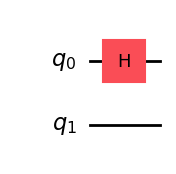

<IPython.core.display.Latex object>

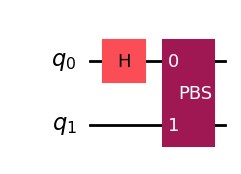

<IPython.core.display.Latex object>

In [31]:
q = QuantumRegister(2, 'q') # register of 2 qubits
# q[0] handedness qubit,|0⟩ left-handed, |1⟩ right-handed
# q[1] direction of propagation qubit, |0⟩ horizontal, |1⟩ vertical
qc = QuantumCircuit(q)

qc.h(q[0]) # Put enantiomer in a superposition of left- and right-handed states
show(qc)

qc.append(PBS, q)
show(qc)

# 3.4. Preparing a permutation symmetric or antisymmetric state
## 3.4.1. Creating random states

In [32]:
def init_random():
  # Create random 1-qubit state s1
  s1 = qi.random_statevector(2)
  display(array_to_latex(s1, prefix="\\text{State 1} =", precision=2))

  # Create random 1-qubit state s2
  s2 = qi.random_statevector(2)
  display(array_to_latex(s2, prefix="\\text{State 2} =", precision =2))
  
  return s1, s2

## 3.4.2. Creating a quantum circuit and initializing qubits

In [33]:
def setup_qc(s1, s2, draw=False):
  init_q1 = Initialize(s1)
  init_q1.label = "init_q1"

  init_q2 = Initialize(s2)
  init_q2.label = "init_q2"

  q = QuantumRegister(3, 'q') # register of 3 qubits
  c = ClassicalRegister(1, name="c") # and 1 classical register
  qc = QuantumCircuit(q,c)
  qc.append(init_q1, [1])
  qc.append(init_q2, [2])
  qc.barrier()
  if draw:
    display(qc.draw(output='mpl'))
  return qc, q, c

## 3.4.3. Creating a circuit that swaps two qubits with a controlled swap gate

In [34]:
def swapper(draw=False):
  q = QuantumRegister(3, 'q') # register of 3 qubits
  qc = QuantumCircuit(q, name='Swapper')
  qc.h(q[0])
  qc.cswap(q[0], q[1], q[2])
  qc.h(q[0])
  if draw:
    print("Swapper circuit")
    display(qc.draw(output='mpl'))
  return qc

Swapper circuit


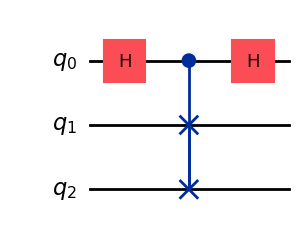

<IPython.core.display.Latex object>

In [35]:
q = QuantumRegister(3, 'q') # register of 3 qubits
qc = QuantumCircuit(q)
qc.append(swapper(draw=True), qargs=q)

# qiskit providers https://docs.quantum.ibm.com/api/migration-guides/qiskit-1.0-features#basicaer-1
U = qi.Operator(qc)

array_to_latex(U, prefix="\\text{swapper unitary} = ", precision = 2)

### Computing the action of the swapper unitary

### Computing the final state when the control qubit $|q_0\rangle$ is measured in state $|0\rangle$

### Computing the final state when the control qubit $|q_0\rangle$ is measured in state $|1\rangle$

## 3.4.4. Post selecting the control qubit until desired state is obtained

In [36]:
def post_select(qc, q, c, symm=True, method='statevector', shots=1, max_iter=20, swap_test=False):
  # Simulating your first quantum program with Qiskit Aer
  # https://qiskit.github.io/qiskit-aer/getting_started.html
  aer_sim = AerSimulator(method=method)
  
  s = qi.Statevector(qc)
  display(array_to_latex(s, prefix="\\text{Initial state} = ", precision = 2))
  done = False
  n_iter = 0
  
  while not done and n_iter < max_iter:
    qc.append(swapper(draw=(n_iter==0)), qargs=q)
    qc.measure(q[0], c[0]) # Measure control qubit q[0]
    
    qc.save_statevector(label=str(n_iter)) # Save the current simulator state vector
    
    new_circuit = transpile(qc, aer_sim)
    job = aer_sim.run(new_circuit, shots=shots)
    result = job.result()
    counts = result.get_counts(qc)
    
    for k, v in counts.items():
      if symm and k == '0' and v > shots/2:
        done = True
      elif not symm and k == '1' and v > shots/2:
        done = True
      
    if not done:
      qc.reset(q[0])
      n_iter += 1
  
  success = proc_result(result, qc, n_iter, counts, max_iter=max_iter, symm=symm, method=method, swap_test=swap_test)
  return result, success

In [37]:
def proc_result(result, qc, n_iter, counts, max_iter=20, symm=True, method='statevector', swap_test=False):
  if symm:
    print("Preparing a permutation symmetric state")
  else:
    print("Preparing a permutation antisymmetric state")
  print("method:", method)
  print("counts: ", counts)
  
  if n_iter >= max_iter:
    print("Post selection unsuccessful iteration {}".format(n_iter))
    success = False
  else:
    print("Post selection successful iteration {}".format(n_iter))
    success = True
    s = result.data()[str(n_iter)]
    factor(s, symm) # Call factor()

    if swap_test:
      swap_check(qc, q, n_iter, symm, s, method=method)
    
    print(" ") # Display Density matrix of the final state
    display(array_to_latex(qi.DensityMatrix(s), prefix="\\text{Density matrix of the final state: }", precision = 2))
    display(plot_state_city(s, title='Cityscape plot of the final state')) # Display Cityscape plot of the final state
    
  return success

In [38]:
def sym_test(s, symm, i0, i1):
  if symm:
    b = np.isclose(np.abs(s[i0]-s[i1]), 0, rtol=_EPS) and np.isclose(np.abs(s[i0]**2 + s[i1]**2), 1, rtol=1e-4)
  else:
    b = np.isclose(np.abs(s[i0]+s[i1]), 0, rtol=_EPS) and np.isclose(np.abs(s[i0]**2 + s[i1]**2), 1, rtol=1e-4)
  return b

In [39]:
def factor(s, symm):
  b0 = np.allclose(s, [1, 0, 0, 0, 0, 0, 0, 0], rtol=_EPS)
  b1 = np.allclose(s, [0, 0, 0, 0, 0, 0, 1, 0], rtol=_EPS)
  b2 = sym_test(s, symm, 2, 4)
  b3 = sym_test(s, symm, 3, 5)
  b4 = sym_test(s, symm, 0, 6)
  b5 = sym_test(s, symm, 1, 7)
  df = {b0: "|00", b1: "|11", b2: "|\\Psi_+", b3: "|\\Psi_-", b4: "|\\Phi_+", b5: "|\\Phi_-"}
  found = False
  for k, v in df.items():
    if not found and symm and k:
      display(array_to_latex([s], prefix = "\\text{Symmetrized state: }" + v + "\\rangle, \\text{  Final state: }" + v + " \\rangle |0 \\rangle =", precision = 2))
      found = True
    elif not found and not symm and k:
      display(array_to_latex([s], prefix = "\\text{Antisymmetrized state: }" + v + "\\rangle, \\text{  Final state: }" + v + " \\rangle |1 \\rangle =", precision = 2))
      found = True
  if not found:
    display(array_to_latex(s, prefix="\\text{Final state} = ", precision = 2))
  return

In [40]:
def swap_check(qc, q, n_iter, symm, s, method='statevector'):
  s21 = swap(qc, q, n_iter, method=method)
  if symm:
    if np.allclose(s-s21, 0, rtol=_EPS):
      print("Swap test confirms that final state is permutation symmetric")
  else:
    if np.allclose(s+s21, 0, rtol=_EPS):
      print("Swap test confirms that final state is permutation asymmetric")
  return

In [41]:
def swap(qc, q, n_iter, method='statevector'):
  aer_sim = AerSimulator(method=method)
  qc.swap(q[1], q[2])
  qc.measure(q[0], c[0]) # Measure control qubit q[0]
  qc.save_statevector(label=str(n_iter+1)) # Save the current simulator state vector
  new_circuit = transpile(qc, aer_sim)
  job = aer_sim.run(new_circuit, shots=1)
  result = job.result()
  s21 = result.data()[str(n_iter+1)]
  return s21

## 3.4.5. Examples of final symmetrized and antisymmetrized states
### Experiment creating a symmetrized state from state $|10\rangle$

<IPython.core.display.Latex object>

Swapper circuit


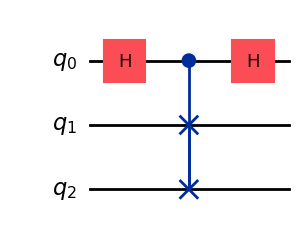

Preparing a permutation symmetric state
method: statevector
counts:  {'0': 1}
Post selection successful iteration 0


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

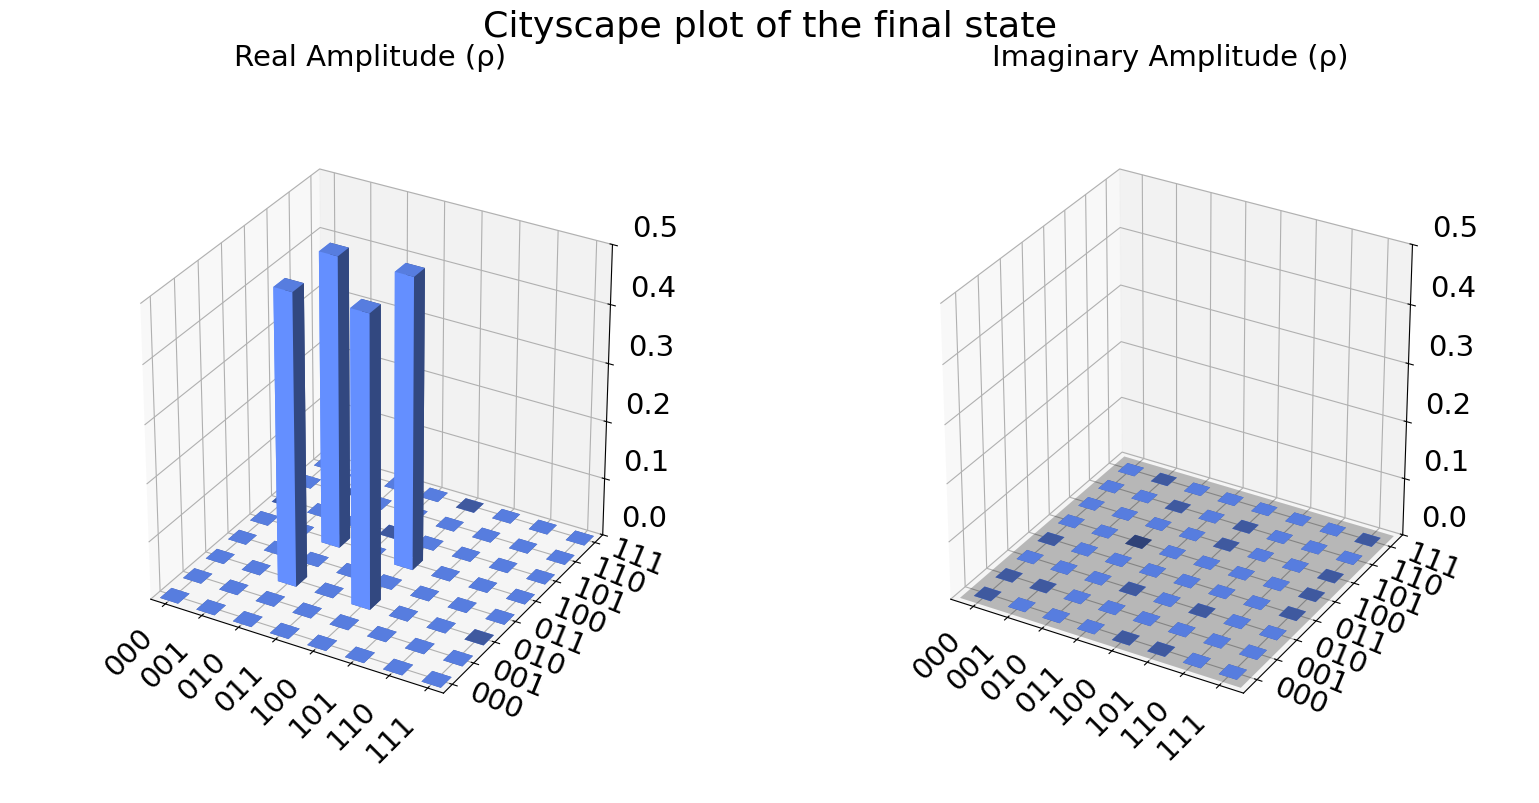

In [42]:
s1 = qi.Statevector([0, 1])
s2 = qi.Statevector([1, 0])
qc, q, c = setup_qc(s1, s2)
result, success = post_select(qc, q, c, symm=True)

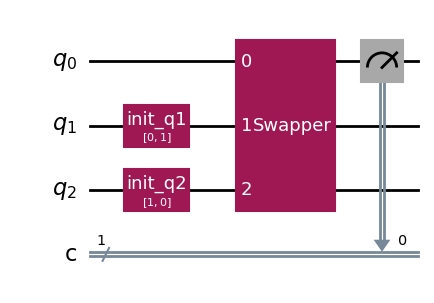

In [43]:
qc.draw(output='mpl', plot_barriers=False)

### Experiment creating an antisymmetrized state from from state $|10\rangle$

<IPython.core.display.Latex object>

Swapper circuit


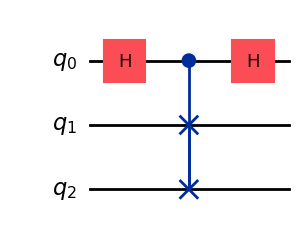

Preparing a permutation antisymmetric state
method: statevector
counts:  {'1': 1}
Post selection successful iteration 1


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

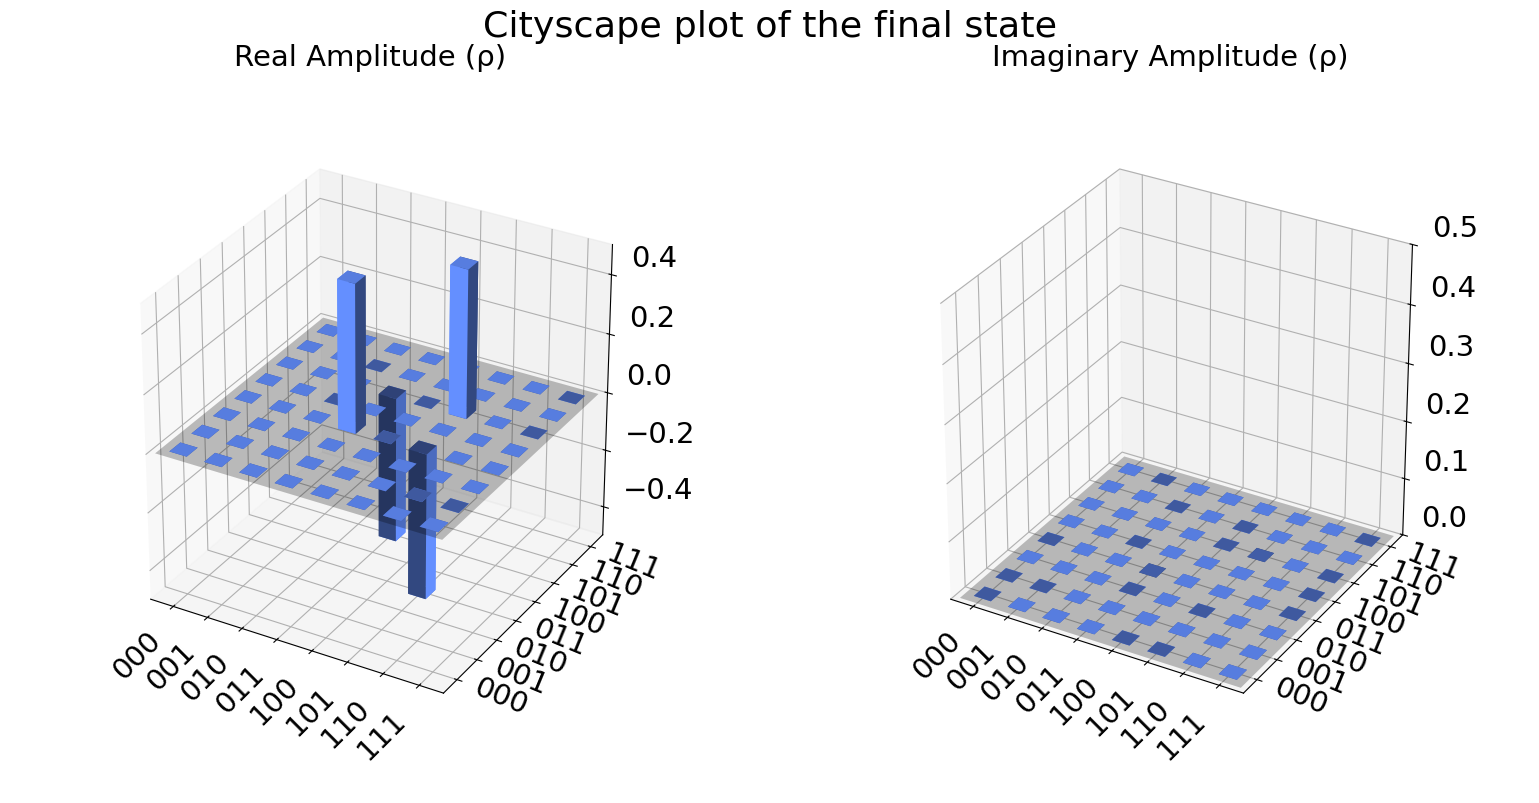

In [44]:
s1 = qi.Statevector([0, 1])
s2 = qi.Statevector([1, 0])
qc, q, c = setup_qc(s1, s2)
result, success = post_select(qc, q, c, symm=False)

### Experiment creating a symmetrized state from qubits initialized with random states

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Swapper circuit


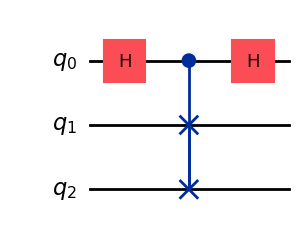

Preparing a permutation symmetric state
method: statevector
counts:  {'0': 1}
Post selection successful iteration 0


<IPython.core.display.Latex object>

Swap test confirms that final state is permutation symmetric
 


<IPython.core.display.Latex object>

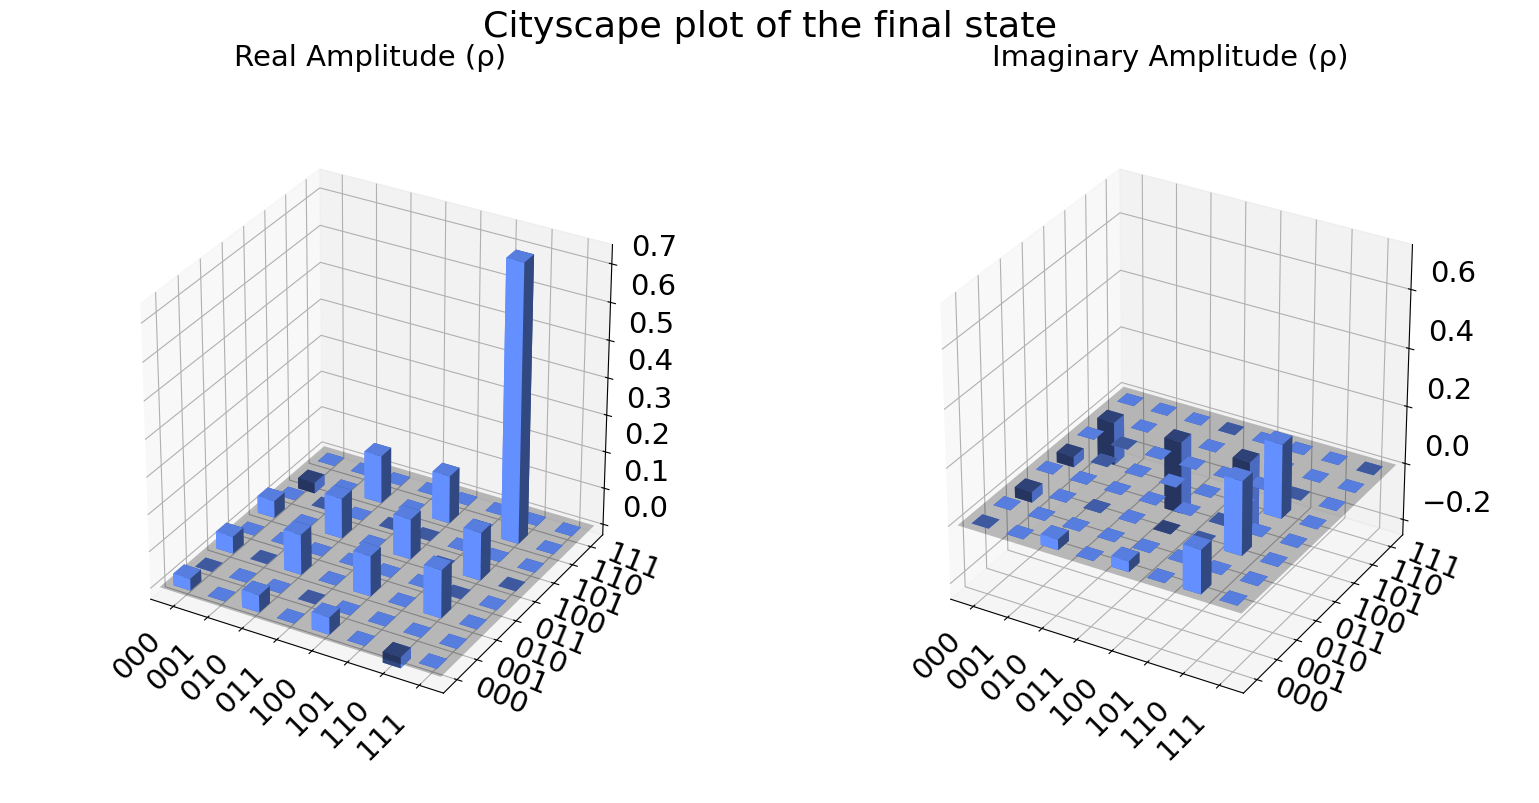

In [45]:
s1, s2 = init_random()
qc, q, c = setup_qc(s1, s2)
result, success = post_select(qc, q, c, symm=True, swap_test=True)

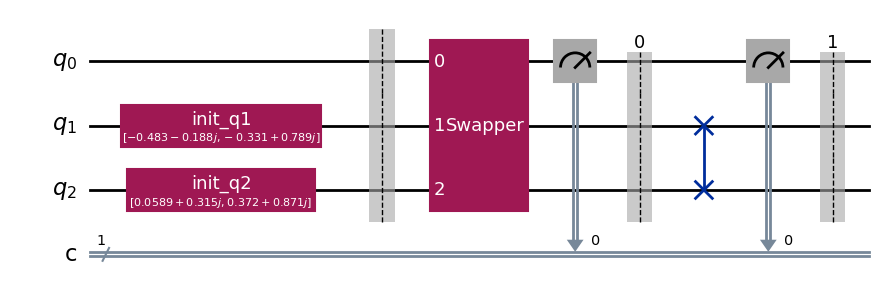

In [46]:
qc.draw(output='mpl')

### Experiment creating an antisymmetrized state from qubits initialized with random states

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Swapper circuit


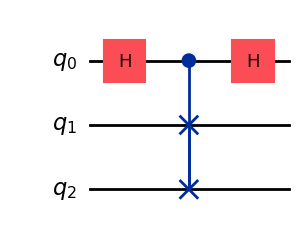

Preparing a permutation antisymmetric state
method: statevector
counts:  {'1': 1}
Post selection successful iteration 6


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

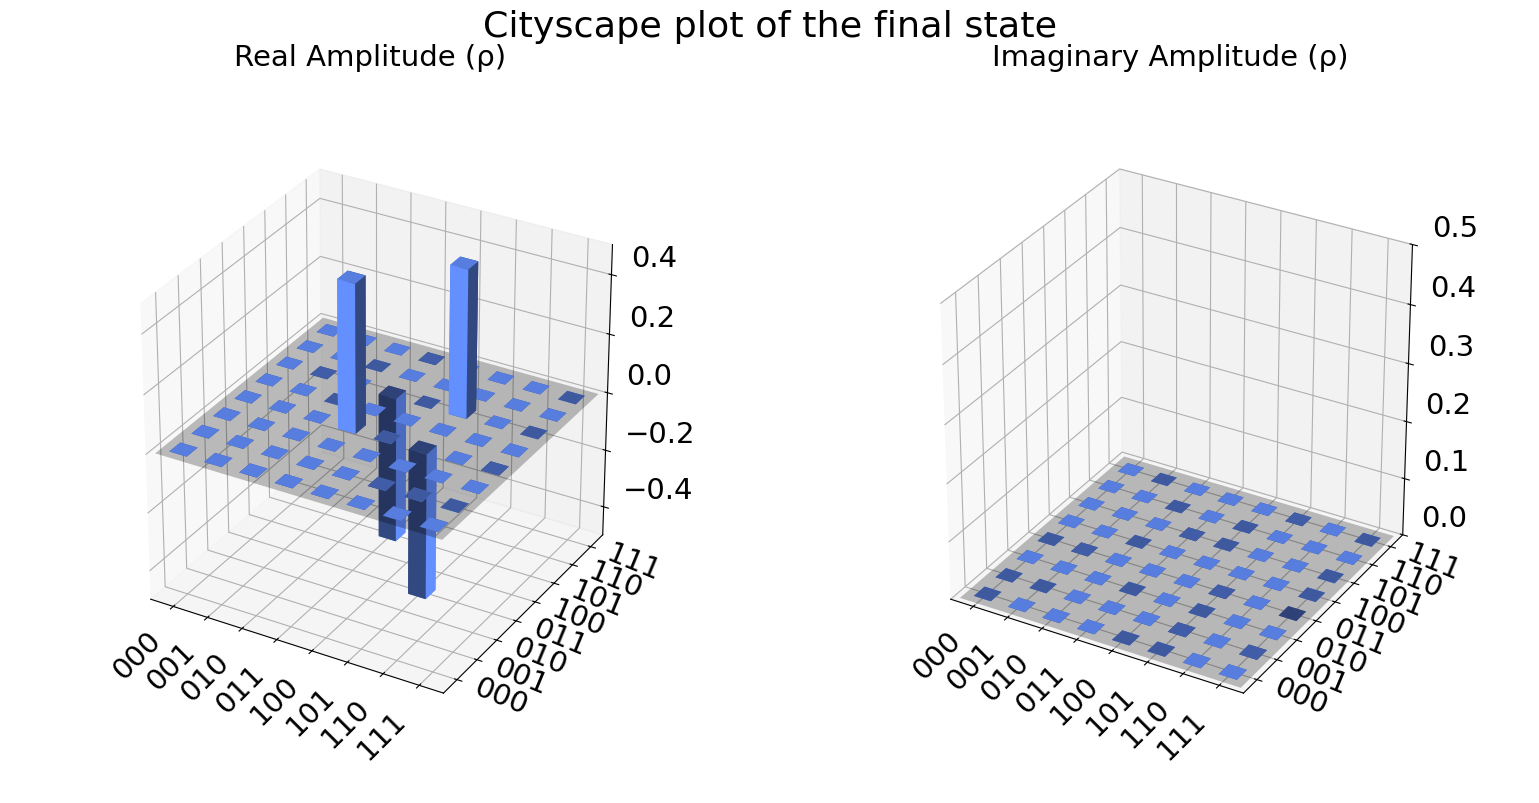

In [47]:
s1, s2 = init_random()
qc, q, c = setup_qc(s1, s2)
result, success = post_select(qc, q, c, symm=False, swap_test=True)

### Experiment creating a symmetrized state from the Bell state $|\Phi_+\rangle$

In [48]:
def setup1_qc(draw=False):
  q = QuantumRegister(3, 'q') # register of 3 qubits
  c = ClassicalRegister(1, name="c") # and 1 classical register
  qc = QuantumCircuit(q,c)
  qc.h(q[1])
  qc.cx(q[1], q[2])
  qc.barrier()
  if draw:
    display(qc.draw(output='mpl'))
  return qc, q, c

<IPython.core.display.Latex object>

Swapper circuit


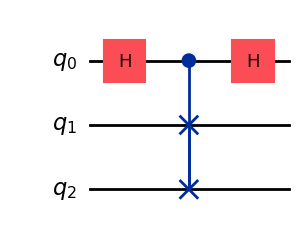

Preparing a permutation symmetric state
method: statevector
counts:  {'0': 1}
Post selection successful iteration 0


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

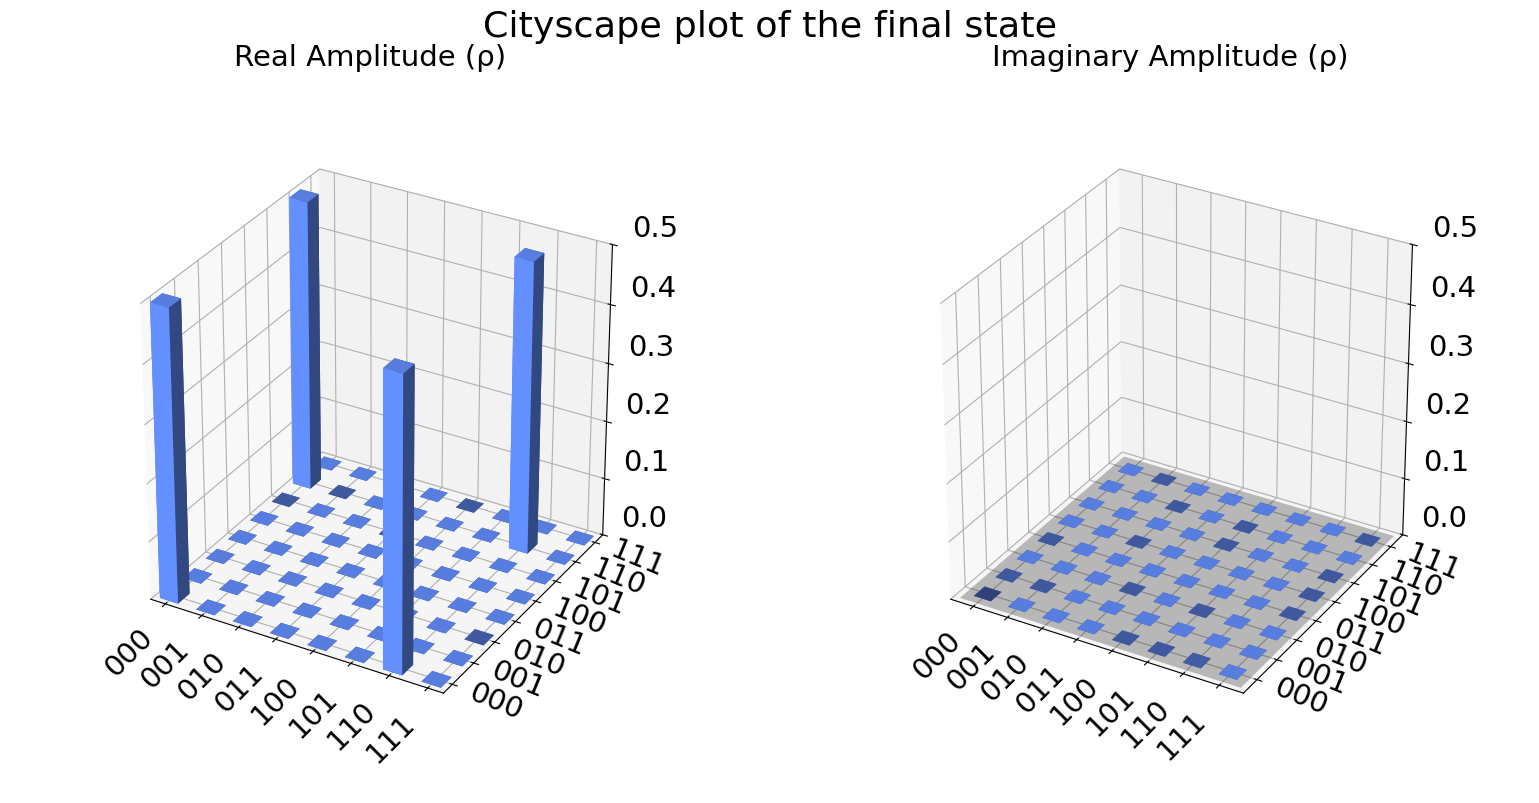

In [49]:
qc, q, c = setup1_qc()
result, success = post_select(qc, q, c, symm=True)

# References
[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[Qiskit] Qiskit, https://qiskit.org/

[QuTiP] QuTiP, Plotting on the Bloch Sphere, https://qutip.readthedocs.io/en/qutip-5.0.x/guide/guide-bloch.html

## Qiskit packages versions

In [52]:
import qiskit
import qiskit_aer

print(f'Qiskit: {qiskit.__version__}')
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit: 2.2.3
Qiskit IBM Runtime: 0.43.1
Qiskit Aer version: 0.17.2


## Show Python version

In [53]:
%%bash
which python
python --version

/home/alain/miniconda3/bin/python
Python 3.13.9
